# 04 - Unsupervised detection trained on normal batches only

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AHichem/industrial-anomaly-detection/blob/main/notebooks/04_unsupervised_pca_autoencoder.ipynb)

**Goal of this notebook**

Notebook 03 showed that a supervised model only recognises the faults it was trained on. Here we do the opposite: the model **only sees normal batches**. It learns what "normal" looks like, and raises an alarm when a window is too different from it. This way, it can also catch faults it has never seen.

1. Same data, same 10 h windows and same train/test split as notebook 03 (to compare fairly).
2. Train on **normal batches only**.
3. **PCA**: compress each window, rebuild it, and measure the rebuild error.
4. **Autoencoder**: same idea, with a small neural network.
5. Compare all models: golden batch, Isolation Forest, Random Forest, PCA, autoencoder.

**Prerequisite:** run notebook 01 once, so that the clean data is cached in Google Drive.

## 1. Loading

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/indpensim')
except ImportError:  # not running in Colab
    DATA_DIR = Path('data')

PROCESS_PARQUET = DATA_DIR / 'indpensim_process.parquet'
assert PROCESS_PARQUET.exists(), 'Run notebook 01 first to create the cached data.'

df = pd.read_parquet(PROCESS_PARQUET)
df['t'] = df['Time (h)'].astype('float64').round(1)  # clean time key, identical across batches
print(df.shape, '-', df['batch_id'].nunique(), 'batches')

Mounted at /content/drive
(113935, 41) - 100 batches


Features naming simplification (same as notebook 03)

In [2]:
INPUTS = {  # Inputs of the controlled system
    'Aeration rate(Fg:L/h)': 'aeration',
    'Agitator RPM(RPM:RPM)': 'agitator_rpm',
    'Sugar feed rate(Fs:L/h)': 'sugar_feed',
    'Acid flow rate(Fa:L/h)': 'acid_flow',
    'Base flow rate(Fb:L/h)': 'base_flow',
    'Heating/cooling water flow rate(Fc:L/h)': 'cooling_water',
    'Heating water flow rate(Fh:L/h)': 'heating_water',
    'Water for injection/dilution(Fw:L/h)': 'dilution_water',
    'Air head pressure(pressure:bar)': 'head_pressure',
    'Dumped broth flow(Fremoved:L/h)': 'dumped_broth',
    'PAA flow(Fpaa:PAA flow (L/h))': 'paa_flow',
    'Oil flow(Foil:L/hr)': 'oil_flow',
    'Ammonia shots(NH3_shots:kgs)': 'nh3_shots',
}
SENSORS = {  # measurements done online
    'Dissolved oxygen concentration(DO2:mg/L)': 'DO2',
    'pH(pH:pH)': 'pH',
    'Temperature(T:K)': 'temperature',
    'carbon dioxide percent in off-gas(CO2outgas:%)': 'CO2_offgas',
    'Oxygen in percent in off-gas(O2:O2  (%))': 'O2_offgas',
    'Vessel Weight(Wt:Kg)': 'weight',
}
COMPUTED = {  # derived from measurements
    'Vessel Volume(V:L)': 'volume',
    'Generated heat(Q:kJ)': 'heat',
    'Oxygen Uptake Rate(OUR:(g min^{-1}))': 'OUR',
    'Carbon evolution rate(CER:g/h)': 'CER',
}
OTHER = {
    'Penicillin concentration(P:g/L)': 'penicillin_true',     # target
    'Fault reference(Fault_ref:Fault ref)': 'fault',          # label
}
rename = {**INPUTS, **SENSORS, **COMPUTED, **OTHER}
missing_cols = [c for c in rename if c not in df.columns]
assert not missing_cols, f'Unexpected column names: {missing_cols}'
df = df.rename(columns=rename)

MONITOR_VARS = list(INPUTS.values()) + list(SENSORS.values()) + list(COMPUTED.values())
print(len(MONITOR_VARS), 'variables available to the monitor')

23 variables available to the monitor


## 2. Time windows (same as notebook 03)

Each batch is cut into 10 h windows. Each window becomes one row: mean and standard deviation of each variable, plus the window position (`window`).

In [3]:
WINDOW_H = 10   # window length in hours

df['window'] = (df['t'] // WINDOW_H).astype(int)   # 0 = 0-10 h, 1 = 10-20 h, ...

windows = df.groupby(['batch_id', 'window'])[MONITOR_VARS].agg(['mean', 'std'])
windows.columns = ['_'.join(c) for c in windows.columns]   # ('DO2', 'mean') -> 'DO2_mean'
windows = windows.fillna(0)

windows['fault'] = df.groupby(['batch_id', 'window'])['fault'].max()   # 1 if the fault is active in the window
windows = windows.reset_index()

print('Windows:', len(windows), '/ faulty windows:', windows['fault'].sum())

Windows: 2362 / faulty windows: 44


## 3. Train on normal batches only

We keep **the same split as notebook 03**, so the test set is identical and the results can be compared.

The difference: the faulty batches of the training set are **removed**. The model never sees a fault.

In [4]:
from sklearn.model_selection import train_test_split

batch_group = df.groupby('batch_id')['group'].first()
all_ids = list(range(1, 101))
fault_ids = list(range(91, 101))

train_ids, test_ids = train_test_split(all_ids, test_size=0.3, stratify=batch_group, random_state=0)   # same split as notebook 03
normal_train_ids = [b for b in train_ids if b not in fault_ids]   # only normal batches
fault_test_ids = [b for b in test_ids if b in fault_ids]

features = windows.columns.drop(['batch_id', 'fault'])
train = windows[windows['batch_id'].isin(normal_train_ids)]
test  = windows[windows['batch_id'].isin(test_ids)].copy()

print(len(normal_train_ids), 'normal batches for training')
print('Faulty batches in test:', fault_test_ids)

63 normal batches for training
Faulty batches in test: [93, 94, 91]


**Scaling.** PCA and neural networks compare distances, so all features must be on the same scale (mean 0, std 1). The scaler is fitted on the normal training batches only.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(train[features])
X_test  = scaler.transform(test[features])

Two small helpers, used for both models:
- `show_results`: false alarm rate and detection rate, as in notebook 03;
- `plot_batches`: true fault vs alarm over time, for each faulty test batch.

In [6]:
def show_results(alarm_col):
    false_alarms = test.loc[test['fault'] == 0, alarm_col].mean() * 100
    detection    = test.loc[test['fault'] == 1, alarm_col].mean() * 100
    print('False alarms:', round(false_alarms, 1), '% of normal windows')
    print('Detection:   ', round(detection, 1), '% of fault windows')
    return round(false_alarms, 1), round(detection, 1)


def plot_batches(alarm_col):
    for b in fault_test_ids:
        one = test[test['batch_id'] == b]
        plt.figure(figsize=(10, 2.5))
        plt.step(one['window'] * WINDOW_H, one['fault'], where='post', label='true fault')
        plt.step(one['window'] * WINDOW_H, one[alarm_col], where='post', label='alarm')
        plt.title(f'Batch {b}')
        plt.xlabel('Time (h)')
        plt.legend()
        plt.show()

## 4. PCA

**Idea:** the 47 features of a normal window are strongly linked (when aeration goes up, DO2 goes up...). PCA finds a few "summary directions" that keep most of the information.

For each window we **compress** it with PCA, then **rebuild** it. A normal window is rebuilt well. A faulty window breaks the usual links between variables, so it is rebuilt badly: **large rebuild error = alarm**.

(Classical PCA monitoring also uses a second statistic, T². We keep only the rebuild error, also called SPE, to stay simple.)

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.9)   # keep enough components for 90 % of the information
pca.fit(X_train)
print(pca.n_components_, 'components instead of', len(features), 'features')

11 components instead of 47 features


**Alarm threshold.** We compute the rebuild error on the normal training windows and take its 99th percentile: by construction, about 1 % of normal windows go above it.

** SPE **

In [8]:
def pca_error(X):
    X_rebuilt = pca.inverse_transform(pca.transform(X))
    return ((X - X_rebuilt) ** 2).mean(axis=1)   # mean squared error per window

threshold_pca = np.percentile(pca_error(X_train), 99)

test['pca_error'] = pca_error(X_test)
test['pca_alarm'] = (test['pca_error'] > threshold_pca).astype(int)

pca_fa, pca_det = show_results('pca_alarm')

False alarms: 1.1 % of normal windows
Detection:    46.2 % of fault windows


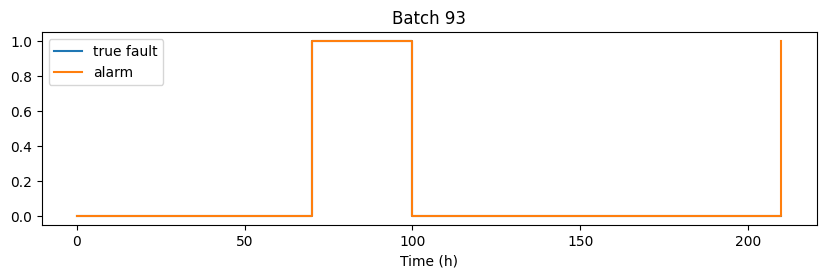

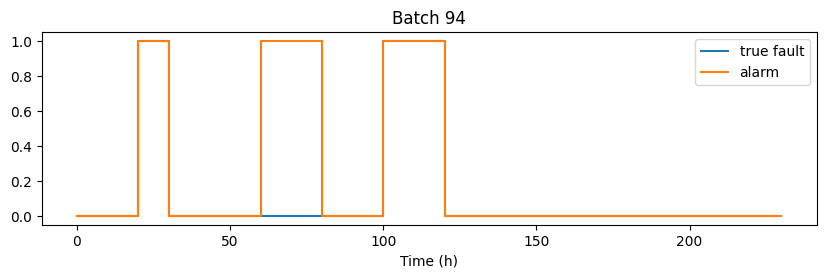

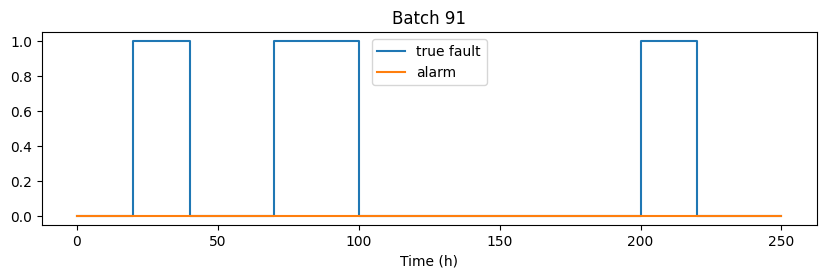

In [9]:
plot_batches('pca_alarm')

**Your turn - interpretation** *(write 2-3 sentences here)*

- How many false alarms and detections compared with the Random Forest (0 % / 23 %)?
- On the plots: is the fault detected at its start, late, or only partly?

**T2**

In [19]:
def pca_t2(X):
    scores = pca.transform(X)
    return (scores ** 2 / pca.explained_variance_).sum(axis=1)   # one score per window


threshold_pca_t2 = np.percentile(pca_t2(X_train), 99)

test['pca_t2'] = pca_t2(X_test)
test['pca_alarm_t2'] = (test['pca_t2'] > threshold_pca_t2).astype(int)

pca_fa_t2, pca_det_t2 = show_results('pca_alarm_t2')

False alarms: 0.6 % of normal windows
Detection:    38.5 % of fault windows


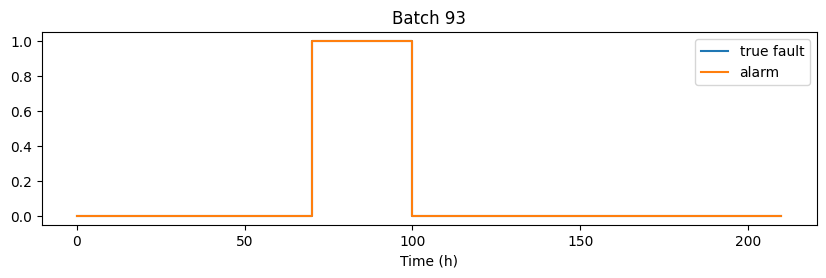

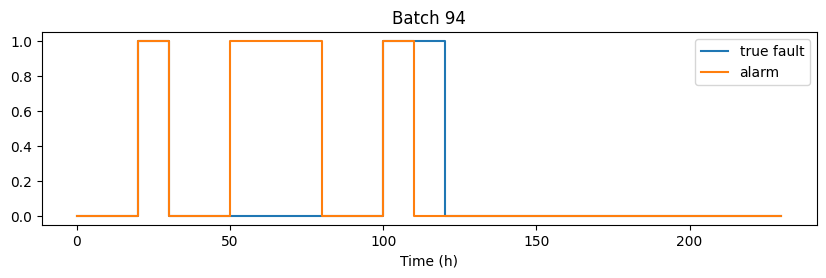

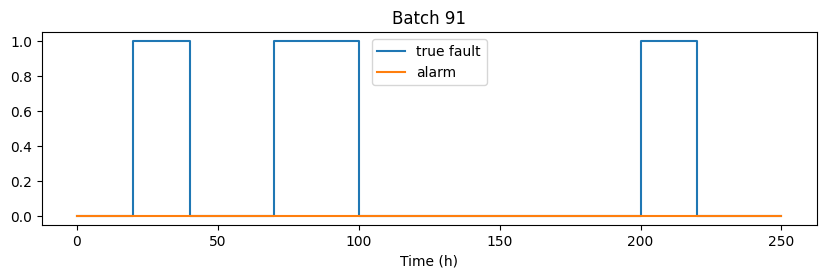

In [20]:
plot_batches('pca_alarm_t2')

** SPE + T2 **

In [21]:
test['pca_alarm_both'] = ((test['pca_alarm'] == 1) | (test['pca_alarm_t2'] == 1)).astype(int)
pca_fa_both, pca_det_both = show_results('pca_alarm_both')

False alarms: 1.4 % of normal windows
Detection:    46.2 % of fault windows


## 5. Autoencoder

**Idea:** same as PCA, but with a small neural network. The network is trained to **rebuild its own input**, through a narrow middle layer (5 neurons) that forces it to compress. Unlike PCA, it can learn curved (non-linear) links between variables.

We build it with Keras (already installed in Colab):
- **encoder**: 47 features → 20 → **5** (the bottleneck, where the window is compressed);
- **decoder**: 5 → 20 → 47 features (the rebuilt window).

In [10]:
from tensorflow import keras

keras.utils.set_random_seed(0)   # same result at every run

n_features = X_train.shape[1]

ae = keras.Sequential([
    keras.Input(shape=(n_features,)),
    keras.layers.Dense(20, activation='relu'),   # encoder
    keras.layers.Dense(5, activation='relu'),    # bottleneck: compression
    keras.layers.Dense(20, activation='relu'),   # decoder
    keras.layers.Dense(n_features),              # rebuilt window
])
ae.compile(optimizer='adam', loss='mse')
ae.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 20)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 47)             │           987 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,172 (8.48 KB)

 Trainable params: 2,172 (8.48 KB)

 Non-trainable params: 0 (0.00 B)

**Training.** Input = target: the network learns to rebuild normal windows. We keep 20 % of the training windows aside (`validation_split`) to check that it does not just memorise.

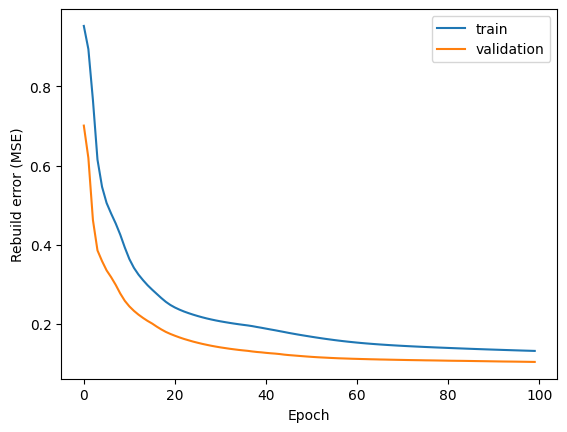

In [11]:
history = ae.fit(X_train, X_train, epochs=100, batch_size=32, validation_split=0.2, verbose=0)

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.xlabel('Epoch')
plt.ylabel('Rebuild error (MSE)')
plt.legend()
plt.show()

**How to read the curve:** both curves should go down and then flatten. If the validation curve goes back up while the train curve keeps going down, the network is memorising (overfitting).

In [12]:
def ae_error(X):
    X_rebuilt = ae.predict(X, verbose=0)
    return ((X - X_rebuilt) ** 2).mean(axis=1)   # mean squared error per window

threshold_ae = np.percentile(ae_error(X_train), 99)

test['ae_error'] = ae_error(X_test)
test['ae_alarm'] = (test['ae_error'] > threshold_ae).astype(int)

ae_fa, ae_det = show_results('ae_alarm')

False alarms: 1.7 % of normal windows
Detection:    46.2 % of fault windows


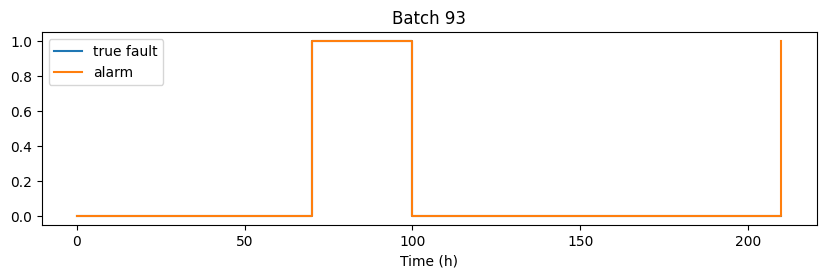

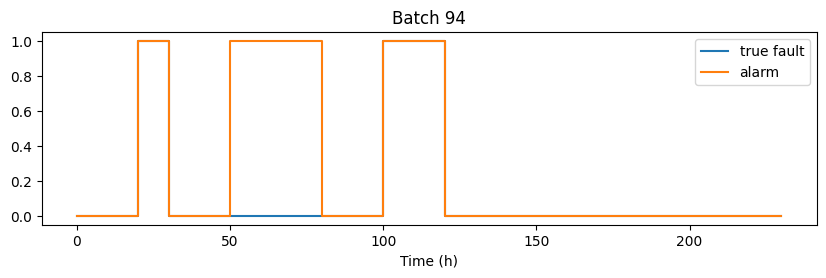

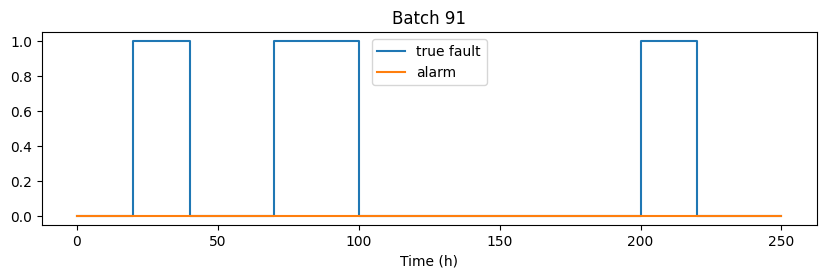

In [13]:
plot_batches('ae_alarm')

**Your turn - interpretation** *(write 1-2 sentences here)*

- Does the autoencoder do better or worse than the PCA?

## 6. Comparison of all models

The golden batch and Isolation Forest results come from notebook 02, the Random Forest from notebook 03.

Careful: notebook 02 measured alarms **per time point**, notebooks 03 and 04 **per 10 h window**. The comparison gives the order of magnitude, not an exact match.

In [22]:
summary = pd.DataFrame({
    'Model':            ['Golden batch (02)', 'Isolation Forest (02)', 'Random Forest (03)', 'PCA', 'PCA T²', 'PCA SPE + T²', 'Autoencoder'],
    'Trained on':       ['normal', 'normal', 'normal + faults', 'normal', 'normal', 'normal', 'normal'],
    'False alarms (%)': [15.5, 1.0, 0.0, pca_fa, pca_fa_t2, pca_fa_both, ae_fa],
    'Detection (%)':    [None, 2.0, 23.1, pca_det,pca_det_t2,pca_det_both, ae_det],
})
summary

,Model,Trained on,False alarms (%),Detection (%)
0,Golden batch (02),normal,15.5,NaN
1,Isolation Forest (02),normal,1.0,2.0
2,Random Forest (03),normal + faults,0.0,23.1
3,PCA,normal,0.6,38.5
4,PCA T²,normal,0.6,38.5
5,PCA SPE + T²,normal,1.4,46.2
6,Autoencoder,normal,1.7,46.2


## 7. Faults never seen

PCA and the autoencoder have **never seen any fault**. So every fault batch is "new" for them, including the faulty batches that were in the training set of notebook 03.

We can therefore test them on **all 10 faulty batches**.

In [24]:
faulty = windows[windows['batch_id'].isin(fault_ids)]
X_faulty = scaler.transform(faulty[features])
is_fault = faulty['fault'] == 1

pca_all = (pca_error(X_faulty) > threshold_pca)[is_fault].mean() * 100
t2_all   = (pca_t2(X_faulty) > threshold_pca_t2)[is_fault].mean() * 100
both_all = ((pca_error(X_faulty) > threshold_pca) | (pca_t2(X_faulty) > threshold_pca_t2))[is_fault].mean() * 100
ae_all  = (ae_error(X_faulty)  > threshold_ae)[is_fault].mean() * 100

print('Detection on all 10 faulty batches:')
print('PCA SPE:        ', round(pca_all, 1), '% of fault windows')
print('PCA T2:        ', round(t2_all, 1), '% of fault windows')
print('PCA SPE + T2:        ', round(both_all, 1), '% of fault windows')
print('Autoencoder:', round(ae_all, 1), '% of fault windows')

Detection on all 10 faulty batches:
PCA SPE:         0.0 % of fault windows
PCA T2:         38.6 % of fault windows
PCA SPE + T2:         38.6 % of fault windows
Autoencoder: 56.8 % of fault windows


**Your turn - interpretation** *(write 1-2 sentences here)*

- Compare with the Random Forest on a fault family it had never seen (section 7 of notebook 03).

## 8. Conclusions

*(Hichem - 3 to 4 bullet points: which model gives the best balance between false alarms and detection, the advantage of training on normal batches only, and the remaining limits.)*